# 06 — Training ConvNeXt-Tiny

Studio Proyek 2 · Klasifikasi 5 jenis sampah (IF25-40401)

## 1. Setup

Semua import, path, dan pengecekan GPU. Split dan transform diambil dari `preprocessing.py`, metrik dari `evaluate.py`.

In [1]:
import gc
import math
import os
import random
import shutil
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import timm
import torch
import torch.nn as nn
from huggingface_hub.utils import logging as hf_logging
from PIL import Image
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
from torch.utils.data import DataLoader
from torchvision import datasets

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import evaluate
from evaluate import metrics
from preprocessing import SEED, get_batch_mix, get_eval_transform, get_train_transform

TRAIN_DIR, VAL_DIR = ROOT / "my_train", ROOT / "my_val"
SUB_DIR, CKPT_DIR = ROOT / "submission", ROOT / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)
CLASSES = ["botol_plastik", "gelas_plastik", "kertas_kardus", "saset_kemasan", "styrofoam"]
NUM_CLASSES = len(CLASSES)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
NUM_WORKERS = 0

hf_logging.set_verbosity_error()

assert torch.cuda.is_available(), "notebook ini butuh GPU CUDA"
device = "cuda"
torch.backends.cudnn.benchmark = True

gpu = torch.cuda.get_device_properties(0)
print(f"torch {torch.__version__} | timm {timm.__version__}")
print(f"GPU   : {gpu.name}, {gpu.total_memory / 1024**3:.1f} GB")

torch 2.11.0+cu128 | timm 1.0.30
GPU   : NVIDIA GeForce RTX 3050 Laptop GPU, 4.0 GB


## 2. Verifikasi dataset

Memakai `my_train/` dan `my_val/` hasil `03_preprocessing.ipynb`. Cek jumlah gambar per kelas dan pastikan semua berkas bisa dibuka.

In [2]:
for d in (TRAIN_DIR, VAL_DIR):
    found = sorted(p.name for p in d.iterdir() if p.is_dir())
    assert found == CLASSES, f"folder kelas di {d} tidak sesuai: {found}"

corrupt = []
print(f"{'kelas':<15} {'train':>6} {'val':>6}")
for c in CLASSES:
    n = {}
    for split, d in (("train", TRAIN_DIR), ("val", VAL_DIR)):
        files = [p for p in (d / c).iterdir() if p.suffix.lower() in IMG_EXTS]
        n[split] = len(files)
        for p in files:
            try:
                with Image.open(p) as im:
                    im.verify()
            except Exception as e:
                corrupt.append((p, repr(e)))
    print(f"{c:<15} {n['train']:>6} {n['val']:>6}")
assert not corrupt, f"ada gambar rusak: {corrupt[:3]}"
print("semua gambar valid.")

kelas            train    val
botol_plastik      445     78
gelas_plastik      443     78
kertas_kardus      311     54
saset_kemasan      573    100
styrofoam          571    100
semua gambar valid.


## 3. Konfigurasi

Konfigurasi hasil perbandingan backbone. Batch 16 × accumulation 2 (batch efektif 32) supaya muat di GPU 4 GB.

In [3]:
CFG = dict(
    arch="convnext_tiny.fb_in22k_ft_in1k",
    img_size=224,
    batch=16,
    accum=2,             # grad accumulation -> batch efektif 32
    lr=1e-4,             # LR backbone di fase penuh
    head_lr_mult=10,     # LR head = lr x 10
    wd=5e-2,
    head_epochs=2,       # fase head: backbone dibekukan
    head_lr=1e-3,
    epochs=20,           # fase penuh: semua layer
    warmup_epochs=1,
    label_smoothing=0.1,
    mix_p=0.5,           # peluang Mixup/CutMix per batch
    ema_decay=0.995,
)
for k, v in CFG.items():
    print(f"{k:<16} {v}")

arch             convnext_tiny.fb_in22k_ft_in1k
img_size         224
batch            16
accum            2
lr               0.0001
head_lr_mult     10
wd               0.05
head_epochs      2
head_lr          0.001
epochs           20
warmup_epochs    1
label_smoothing  0.1
mix_p            0.5
ema_decay        0.995


## 4. Transform & DataLoader

Train memakai augmentasi kuat dari `preprocessing.py` (`strong=True`), val memakai `get_eval_transform()` yang nanti ditulis ulang ke `get_transform()` submission.

In [4]:
train_ds = datasets.ImageFolder(TRAIN_DIR, transform=get_train_transform(CFG["img_size"], strong=True))
val_ds = datasets.ImageFolder(VAL_DIR, transform=get_eval_transform(CFG["img_size"]))
assert train_ds.classes == CLASSES == val_ds.classes, "urutan kelas tidak sesuai kontrak submission!"

kw = dict(num_workers=NUM_WORKERS, pin_memory=True)
train_dl = DataLoader(train_ds, batch_size=CFG["batch"], shuffle=True, drop_last=True, **kw)
val_dl = DataLoader(val_ds, batch_size=64, shuffle=False, **kw)

print("class_to_idx:", train_ds.class_to_idx)
print(f"train: {len(train_ds)} gambar, {len(train_dl)} batch | val: {len(val_ds)} gambar, {len(val_dl)} batch")

class_to_idx: {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}
train: 2343 gambar, 146 batch | val: 410 gambar, 7 batch


## 5. Model

ConvNeXt-Tiny pretrained ImageNet-21k dengan head baru 5 kelas. Parameter dibagi ke beberapa group: backbone dan head beda LR, bias/norm tanpa weight decay.

In [5]:
def build_model(pretrained=True):
    return timm.create_model(CFG["arch"], pretrained=pretrained, num_classes=NUM_CLASSES)


def param_groups(model):
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    groups = {(h, d): [] for h in (False, True) for d in (False, True)}  # (head?, decay?)
    for p in model.parameters():
        groups[(id(p) in head_ids, p.ndim > 1)].append(p)  # bias & norm (ndim <= 1) tanpa weight decay
    return [
        dict(params=params, lr=CFG["lr"] * (CFG["head_lr_mult"] if is_head else 1),
             weight_decay=CFG["wd"] if decay else 0.0)
        for (is_head, decay), params in groups.items() if params
    ]


_m = build_model()
print(f"parameter total : {sum(p.numel() for p in _m.parameters()) / 1e6:.1f} M")
print("head            :", _m.get_classifier())
del _m

parameter total : 27.8 M
head            : Linear(in_features=768, out_features=5, bias=True)


## 6. Fungsi training

Fungsi bantu untuk evaluasi (AMP), jadwal LR warmup + cosine, dan satu epoch training dengan Mixup/CutMix, AMP, grad accumulation, serta update EMA.

In [6]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16):
            ps += model(x).argmax(1).cpu().tolist()
        ys += y.tolist()
    return metrics(ys, ps)


def warmup_cosine(total_steps, warmup_steps):
    def f(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        t = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * t))
    return f


def run_epoch(model, opt, sched=None, ema=None):
    model.train()
    total, n = 0.0, 0
    opt.zero_grad(set_to_none=True)
    for i, (x, y) in enumerate(train_dl):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        x, y = mix(x, y)  # Mixup/CutMix untuk sebagian batch (label jadi lunak)
        x = x.to(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = loss_fn(model(x), y)
        scaler.scale(loss / CFG["accum"]).backward()
        if (i + 1) % CFG["accum"] == 0 or i + 1 == len(train_dl):
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)
            if sched is not None:
                sched.step()
            if ema is not None:
                ema.update_parameters(model)
        total += loss.item() * len(x)
        n += len(x)
    return total / n

## 7. Training

Fase head (backbone beku) lalu fase penuh dengan warmup + cosine dan EMA.

In [7]:
set_seed(SEED)
model = build_model().to(device, memory_format=torch.channels_last)
loss_fn = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
mix = get_batch_mix(NUM_CLASSES, p=CFG["mix_p"])
scaler = torch.amp.GradScaler("cuda")
torch.cuda.reset_peak_memory_stats()

best = dict(f1=-1.0, src=None, epoch=None, state=None)
history = []


def log_epoch(phase, ep, loss, m, m_ema, t0):
    history.append(dict(phase=phase, epoch=ep, loss=loss, f1=m["macro_f1"], acc=m["accuracy"],
                        f1_ema=m_ema["macro_f1"] if m_ema else None))
    flag = ""
    for src, mm, net in (("raw", m, model), ("ema", m_ema, ema.module if m_ema else None)):
        if mm and mm["macro_f1"] > best["f1"]:
            best.update(f1=mm["macro_f1"], src=src, epoch=f"{phase}{ep}",
                        state={k: v.detach().cpu().clone() for k, v in net.state_dict().items()})
            flag = f"  <- disimpan ({src})"
    ema_txt = f" | EMA {m_ema['macro_f1']:.4f}" if m_ema else ""
    print(f"[{phase}] ep {ep:2d}  loss {loss:.4f} | F1 {m['macro_f1']:.4f} acc {m['accuracy']:.4f}{ema_txt} | "
          f"{time.time() - t0:.0f}s, GPU {torch.cuda.max_memory_allocated() / 1024**3:.1f} GB{flag}")


# Fase head: backbone dibekukan, hanya head yang dilatih
ema = None
head_ids = {id(p) for p in model.get_classifier().parameters()}
for p in model.parameters():
    p.requires_grad = id(p) in head_ids
opt = torch.optim.AdamW(model.get_classifier().parameters(), lr=CFG["head_lr"], weight_decay=CFG["wd"])
t_start = time.time()
for ep in range(1, CFG["head_epochs"] + 1):
    t0 = time.time()
    loss = run_epoch(model, opt)
    log_epoch("head", ep, loss, evaluate_model(model, val_dl), None, t0)

# Fase penuh: semua layer, LR head lebih besar, warmup + cosine per langkah optimizer, EMA bobot
for p in model.parameters():
    p.requires_grad = True
opt = torch.optim.AdamW(param_groups(model))
steps_per_epoch = math.ceil(len(train_dl) / CFG["accum"])
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, warmup_cosine(steps_per_epoch * CFG["epochs"], steps_per_epoch * CFG["warmup_epochs"]))
ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(CFG["ema_decay"]), use_buffers=True)
for ep in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    loss = run_epoch(model, opt, sched, ema)
    log_epoch("full", ep, loss, evaluate_model(model, val_dl), evaluate_model(ema.module, val_dl), t0)

torch.save(best["state"], CKPT_DIR / "convnext_t_nb07.pth")
print(f"\nMacro-F1 val terbaik: {best['f1']:.4f} ({best['src']}, epoch {best['epoch']}), "
      f"{(time.time() - t_start) / 60:.1f} menit -> checkpoints/convnext_t_nb07.pth")

[head] ep  1  loss 0.9149 | F1 0.9342 acc 0.9366 | 65s, GPU 0.7 GB  <- disimpan (raw)
[head] ep  2  loss 0.7778 | F1 0.9455 acc 0.9488 | 40s, GPU 0.7 GB  <- disimpan (raw)
[full] ep  1  loss 0.7209 | F1 0.9547 acc 0.9561 | EMA 0.9475 | 68s, GPU 1.5 GB  <- disimpan (raw)
[full] ep  2  loss 0.6780 | F1 0.9666 acc 0.9683 | EMA 0.9556 | 49s, GPU 1.5 GB  <- disimpan (raw)
[full] ep  3  loss 0.6287 | F1 0.9549 acc 0.9585 | EMA 0.9561 | 49s, GPU 1.5 GB
[full] ep  4  loss 0.6211 | F1 0.9591 acc 0.9634 | EMA 0.9606 | 49s, GPU 1.5 GB
[full] ep  5  loss 0.6229 | F1 0.9632 acc 0.9659 | EMA 0.9624 | 49s, GPU 1.5 GB
[full] ep  6  loss 0.6184 | F1 0.9571 acc 0.9585 | EMA 0.9622 | 50s, GPU 1.5 GB
[full] ep  7  loss 0.6343 | F1 0.9659 acc 0.9659 | EMA 0.9659 | 49s, GPU 1.5 GB
[full] ep  8  loss 0.6160 | F1 0.9663 acc 0.9683 | EMA 0.9662 | 49s, GPU 1.5 GB
[full] ep  9  loss 0.5519 | F1 0.9690 acc 0.9707 | EMA 0.9691 | 49s, GPU 1.5 GB  <- disimpan (ema)
[full] ep 10  loss 0.5881 | F1 0.9668 acc 0.9683 | 

## 8. Kurva training

Macro-F1 val per epoch untuk bobot biasa dan EMA di fase penuh.

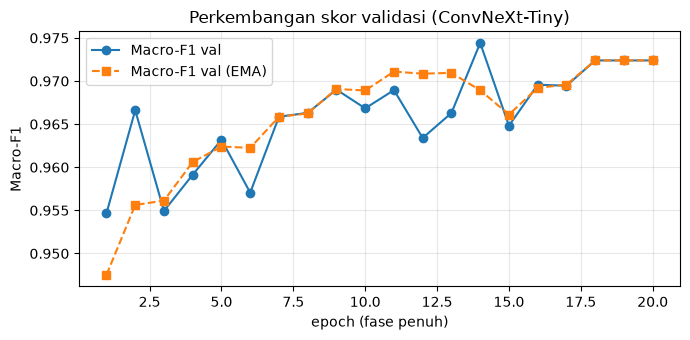

In [8]:
full = [h for h in history if h["phase"] == "full"]
ep = [h["epoch"] for h in full]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ep, [h["f1"] for h in full], "o-", label="Macro-F1 val")
ax.plot(ep, [h["f1_ema"] for h in full], "s--", label="Macro-F1 val (EMA)")
ax.set_xlabel("epoch (fase penuh)")
ax.set_ylabel("Macro-F1")
ax.set_title("Perkembangan skor validasi (ConvNeXt-Tiny)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Evaluasi model terbaik

Muat bobot terbaik lalu hitung Macro-F1, akurasi, F1 per kelas, dan confusion matrix pada `my_val/`.

Macro-F1 : 0.9744
Akurasi  : 0.9756
  F1 botol_plastik   0.9935
  F1 gelas_plastik   0.9512
  F1 kertas_kardus   0.9630
  F1 saset_kemasan   0.9796
  F1 styrofoam       0.9848


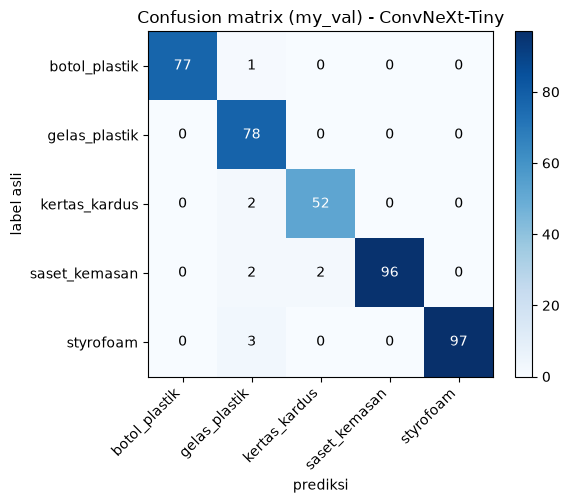

In [9]:
model = build_model(pretrained=False)
model.load_state_dict(best["state"])
model.to(device, memory_format=torch.channels_last)
ema = opt = sched = None  # lepas memori training
gc.collect()
torch.cuda.empty_cache()

m = evaluate_model(model, val_dl)
print(f"Macro-F1 : {m['macro_f1']:.4f}")
print(f"Akurasi  : {m['accuracy']:.4f}")
for c, f in m["per_class_f1"].items():
    print(f"  F1 {c:<15} {f:.4f}")

cm = np.array(m["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("prediksi")
ax.set_ylabel("label asli")
ax.set_title("Confusion matrix (my_val) - ConvNeXt-Tiny")
fig.colorbar(im)
plt.tight_layout()
plt.show()

## 10. Contoh tebakan benar dan salah

Semua tebakan salah di `my_val/` ditampilkan, diurutkan dari yang paling yakin, lalu 12 contoh tebakan benar yang dipilih acak. Judul gambar berisi label asli, prediksi, dan keyakinan model (hijau = benar, merah = salah).

benar: 400 | salah: 10 dari 410 gambar


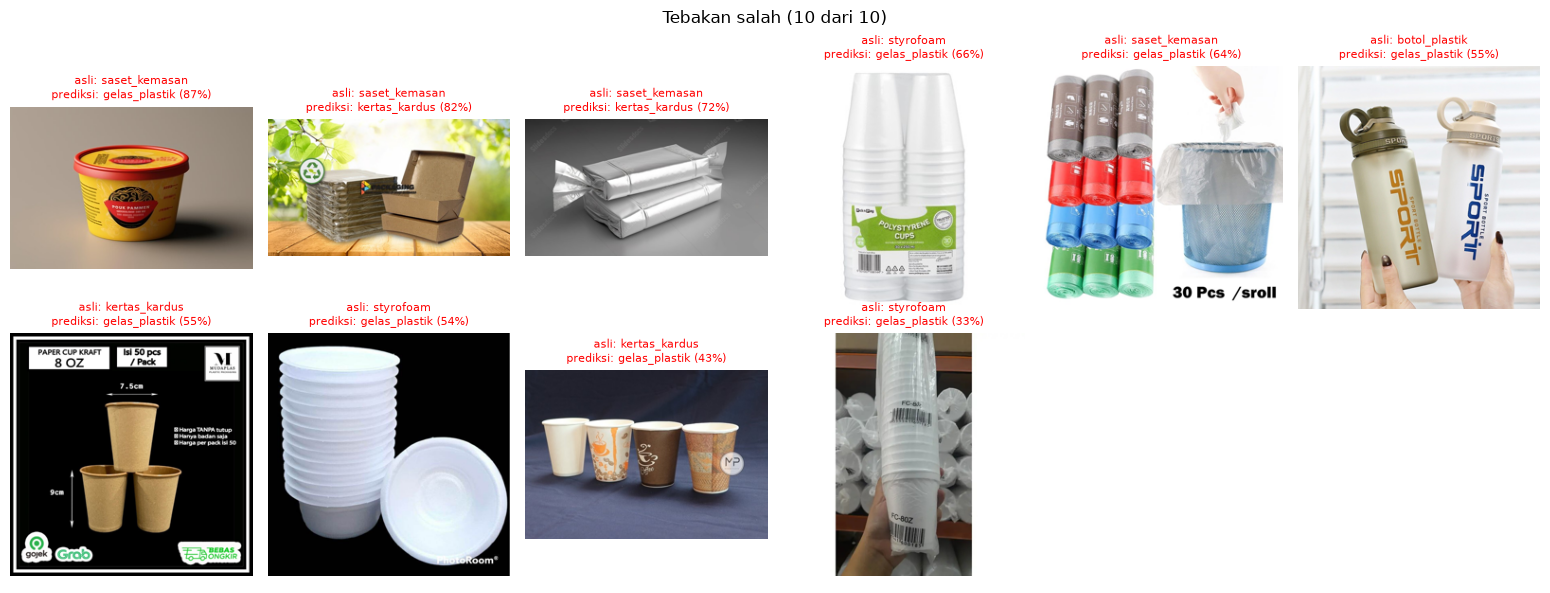

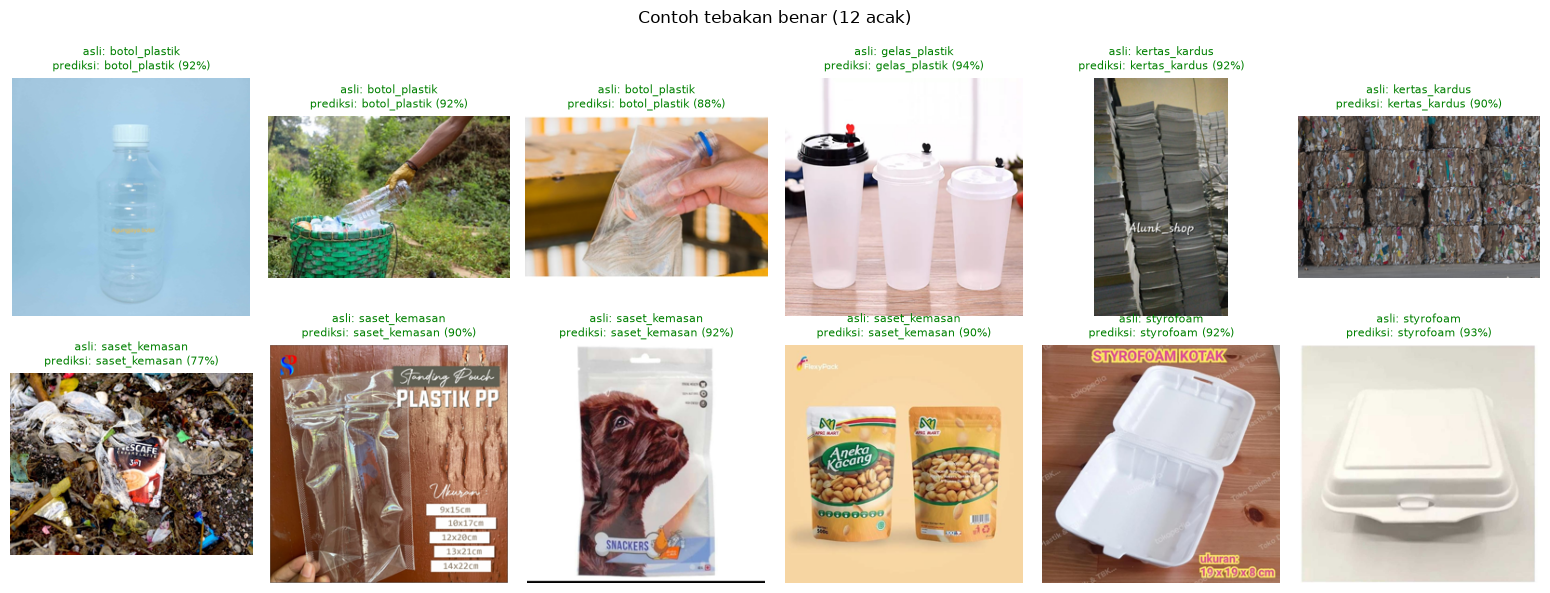

In [10]:
@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    out = []
    for x, _ in loader:
        x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(x).float().softmax(1).cpu())
    return torch.cat(out).numpy()


probs = predict_probs(model, val_dl)  # val_dl tidak diacak, urutannya sama dengan val_ds.samples
y_true = np.array([y for _, y in val_ds.samples])
y_pred, conf = probs.argmax(1), probs.max(1)
right, wrong = np.where(y_pred == y_true)[0], np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-conf[wrong])]  # paling yakin tapi salah di depan
print(f"benar: {len(right)} | salah: {len(wrong)} dari {len(y_true)} gambar")


def show_grid(idx, title, cols=6):
    rows = math.ceil(len(idx) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 3.0 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, idx):
        with Image.open(val_ds.samples[i][0]) as im:
            im = im.convert("RGB")
            im.thumbnail((256, 256))
        ax.imshow(im)
        ax.set_title(f"asli: {CLASSES[y_true[i]]}\nprediksi: {CLASSES[y_pred[i]]} ({conf[i]:.0%})",
                     fontsize=8, color="green" if y_pred[i] == y_true[i] else "red")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


if len(wrong):
    show_grid(wrong[:24], f"Tebakan salah ({min(len(wrong), 24)} dari {len(wrong)})")
rng = np.random.default_rng(SEED)
show_grid(np.sort(rng.choice(right, size=min(12, len(right)), replace=False)), "Contoh tebakan benar (12 acak)")

## 11. Tulis berkas submission

Submission yang ada dinilai dulu di `my_val/`; berkas baru hanya ditulis kalau Macro-F1-nya lebih tinggi, dan yang lama dicadangkan ke `checkpoints/submission_backup/`.

In [11]:
MODEL_PY = '''# Submission Studio 2 - ConvNeXt-Tiny (timm convnext_tiny.fb_in22k_ft_in1k), notebook 07.

import timm
from torchvision import transforms

NUM_CLASSES = 5


def get_model():
    # Arsitektur saja: tanpa mengunduh bobot (evaluate.py yang memuat model.pth).
    return timm.create_model("convnext_tiny.fb_in22k_ft_in1k", pretrained=False, num_classes=NUM_CLASSES)


def get_transform():
    # Harus sama dengan transform validasi saat training (get_eval_transform(224)).
    return transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
'''

# Skor submission yang sekarang (pakai loader resmi evaluate.py)
old_model, old_tf = evaluate.load_submission(SUB_DIR, device)
old_dl = DataLoader(datasets.ImageFolder(VAL_DIR, transform=old_tf), batch_size=64, shuffle=False, **kw)
old_f1 = evaluate_model(old_model.to(memory_format=torch.channels_last), old_dl)["macro_f1"]
del old_model, old_dl
torch.cuda.empty_cache()
print(f"submission sekarang: Macro-F1 {old_f1:.4f} | model baru: {m['macro_f1']:.4f}")

if m["macro_f1"] <= old_f1:
    print("model baru tidak lebih baik -> submission tidak diubah (bobot baru tetap ada di checkpoints/)")
else:
    backup = CKPT_DIR / "submission_backup"
    if backup.exists():
        shutil.rmtree(backup)
    shutil.copytree(SUB_DIR, backup, ignore=shutil.ignore_patterns("__pycache__"))
    (SUB_DIR / "model.py").write_text(MODEL_PY, encoding="utf-8")
    (SUB_DIR / "requirements.txt").write_text("timm\n", encoding="utf-8")
    state = {k: v.detach().cpu().half() if v.is_floating_point() else v.detach().cpu()
             for k, v in model.state_dict().items()}
    torch.save(state, SUB_DIR / "model.pth")
    print(f"submission diganti (lama dicadangkan ke {backup}); model.pth {(SUB_DIR / 'model.pth').stat().st_size / 1e6:.1f} MB")

    # Cek kontrak: get_transform() di model.py identik dengan transform val saat training
    _, new_tf = evaluate.load_submission(SUB_DIR, "cpu")
    with Image.open(next(VAL_DIR.rglob("*.jpg"))) as im:
        im = im.convert("RGB")
        assert torch.equal(new_tf(im), get_eval_transform(CFG["img_size"])(im)), "get_transform() tidak sama!"
    print("OK: get_transform() identik dengan transform val")

submission sekarang: Macro-F1 0.9774 | model baru: 0.9744
model baru tidak lebih baik -> submission tidak diubah (bobot baru tetap ada di checkpoints/)


## 12. Uji dengan `evaluate.py`

`evaluate.main()` dijalankan di kernel ini (bukan subprocess) supaya PyTorch dan CUDA tidak dimuat dua kali. Hasilnya harus sama dengan skor submission di cell 11.

In [12]:
model = None
gc.collect()
torch.cuda.empty_cache()

_argv, t0 = sys.argv, time.time()
sys.argv = ["evaluate.py", "--submission", str(SUB_DIR), "--data", str(VAL_DIR)]
try:
    evaluate.main()
finally:
    sys.argv = _argv
print(f"\nwaktu evaluasi: {time.time() - t0:.0f} detik")

device=cuda  gambar=410

Macro-F1 : 0.9774
Akurasi  : 0.9780
  F1 botol_plastik   0.9873
  F1 gelas_plastik   0.9873
  F1 kertas_kardus   0.9636
  F1 saset_kemasan   0.9583
  F1 styrofoam       0.9901
Confusion matrix (baris = label asli, kolom = prediksi):
  botol_plastik   [78, 0, 0, 0, 0]
  gelas_plastik   [0, 78, 0, 0, 0]
  kertas_kardus   [0, 1, 53, 0, 0]
  saset_kemasan   [2, 1, 3, 92, 2]
  styrofoam       [0, 0, 0, 0, 100]

waktu evaluasi: 24 detik
